In [7]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from importlib import reload

from modules import data_preprocessing as dataPrep
from modules import plotting_functions as plf

In [8]:
df = pd.read_csv('data/annotations_RPN_75mm_final.csv')
df = df.dropna(subset=['radius_pts'])
df['radius_pts'] = df['radius_pts'].astype(int)
dataPrep.compute_radius_from_diameter(df)
df

,tumor_id,case_id,tumor_instance,kidney_instance,calculated_diameter_mm,spacing_z,spacing_y,spacing_x,position,invasion,radius_pts,approved_for_training,Unnamed: 12,computed_radius_points
0,case_00000_t1,case_00000,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,31.20,0.5,0.919922,0.919922,Peripheral,Noninvasive,0,True,NaN,1
1,case_00001_t1,case_00001,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,18.06,0.5,0.798828,0.798828,Peripheral,Noninvasive,0,True,NaN,0
2,case_00001_t2,case_00001,tumor_instance-2_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,25.34,0.5,0.798828,0.798828,Peripheral,Invasive,0,True,NaN,1
3,case_00002_t1,case_00002,tumor_instance-1_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,49.03,1.0,0.939453,0.939453,Peripheral,Semi-invasive,1,True,NaN,1
4,case_00003_t1,case_00003,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,32.72,1.0,0.855469,0.855469,Peripheral,Noninvasive,1,True,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
429,case_00586_t3,case_00586,tumor_instance-3_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,20.16,3.0,0.781250,0.781250,Peripheral,Noninvasive,0,True,NaN,0
430,case_00586_t1,case_00586,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,20.73,3.0,0.781250,0.781250,Peripheral,Noninvasive,0,True,NaN,0
431,case_00586_t2,case_00586,tumor_instance-2_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,27.98,3.0,0.781250,0.781250,Peripheral,Noninvasive,0,True,NaN,1
432,case_00587_t1,case_00587,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,21.96,5.0,0.800781,0.800781,Peripheral,Noninvasive,0,True,NaN,0


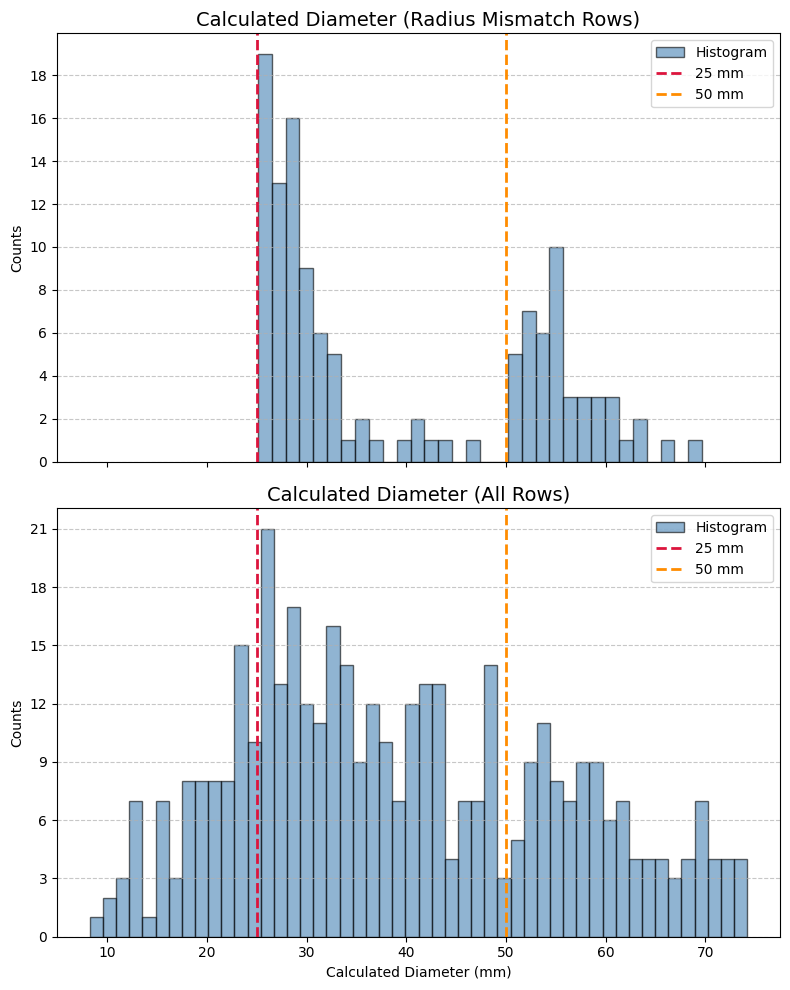

,tumor_id,case_id,tumor_instance,kidney_instance,calculated_diameter_mm,spacing_z,spacing_y,spacing_x,position,invasion,radius_pts,approved_for_training,Unnamed: 12,computed_radius_points
0,case_00000_t1,case_00000,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,31.20,0.5,0.919922,0.919922,Peripheral,Noninvasive,0,True,NaN,1
2,case_00001_t2,case_00001,tumor_instance-2_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,25.34,0.5,0.798828,0.798828,Peripheral,Invasive,0,True,NaN,1
13,case_00014_t1,case_00014,tumor_instance-1_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,29.58,1.0,0.849609,0.849609,Peripheral,Noninvasive,0,True,NaN,1
15,case_00016_t1,case_00016,tumor_instance-1_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,53.90,2.5,0.650391,0.650391,Hilar,Semi-invasive,1,True,NaN,2
24,case_00027_t1,case_00027,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,28.54,0.5,0.894531,0.894531,Peripheral,Noninvasive,0,True,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
414,case_00565_t2,case_00565,tumor_instance-2_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,25.76,5.0,0.850000,0.850000,Peripheral,Semi-invasive,0,True,NaN,1
415,case_00566_t1,case_00566,tumor_instance-1_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,26.36,2.0,0.976562,0.976562,Peripheral,Noninvasive,0,True,NaN,1
418,case_00574_t1,case_00574,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,26.49,5.0,0.761719,0.761719,Hilar,Semi-invasive,0,True,NaN,1
421,case_00579_t1,case_00579,tumor_instance-1_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,28.97,3.0,0.939453,0.939453,Peripheral,Noninvasive,0,True,NaN,1


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Data extraction
mismatch_df = df[df['radius_pts'] != df['computed_radius_points']]
data_mismatch = mismatch_df['calculated_diameter_mm']
data_all = df['calculated_diameter_mm']

# --- Plotting ---
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(8, 10), sharex=True)

# Subplot 1: Mismatched Rows
ax1.hist(
    data_mismatch, 
    bins=32, 
    alpha=0.6, 
    color='steelblue', 
    edgecolor='black',
    label='Histogram'
)
ax1.axvline(25, color='crimson', linestyle='--', linewidth=2, label='25 mm')
ax1.axvline(50, color='darkorange', linestyle='--', linewidth=2, label='50 mm')
ax1.set_title('Calculated Radius (Radius Mismatch Rows)', fontsize=14)
ax1.set_ylabel('Counts')
ax1.legend(loc='upper right')
ax1.grid(axis='y', linestyle='--', alpha=0.7)
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))

# Subplot 2: All Rows
ax2.hist(
    data_all, 
    bins=50, 
    alpha=0.6, 
    color='steelblue', 
    edgecolor='black',
    label='Histogram'
)
ax2.axvline(25, color='crimson', linestyle='--', linewidth=2, label='25 mm')
ax2.axvline(50, color='darkorange', linestyle='--', linewidth=2, label='50 mm')
ax2.set_title('Calculated Radius (all cases)', fontsize=14)
ax2.set_ylabel('Counts')
ax2.set_xlabel('Calculated Diameter (mm)')
ax2.legend(loc='upper right')
ax2.grid(axis='y', linestyle='--', alpha=0.7)
ax2.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig("figures/calculated_diameter_mismatch.png")
plt.show()

mismatch_df

In [10]:
# Calculate counts
mismatch_count = (df['radius_pts'] != df['computed_radius_points']).sum()
total_rows = len(df)
mismatch_pct = (mismatch_count / total_rows) * 100

# Print results
print(f"Mismatched rows: {mismatch_count} / {total_rows} ({mismatch_pct:.2f}%)")

Mismatched rows: 123 / 405 (30.37%)


In [11]:
for index, row in mismatch_df.iterrows():
    print(list(row[['calculated_diameter_mm', 'case_id','tumor_instance','kidney_instance', 'radius_pts']]))

[31.2, 'case_00000', 'tumor_instance-1_annotation-1.nii.gz', 'kidney_instance-1_annotation-1.nii.gz', 0]
[25.34, 'case_00001', 'tumor_instance-2_annotation-1.nii.gz', 'kidney_instance-1_annotation-1.nii.gz', 0]
[29.58, 'case_00014', 'tumor_instance-1_annotation-1.nii.gz', 'kidney_instance-2_annotation-1.nii.gz', 0]
[53.9, 'case_00016', 'tumor_instance-1_annotation-1.nii.gz', 'kidney_instance-2_annotation-1.nii.gz', 1]
[28.54, 'case_00027', 'tumor_instance-1_annotation-1.nii.gz', 'kidney_instance-1_annotation-1.nii.gz', 0]
[27.95, 'case_00033', 'tumor_instance-1_annotation-1.nii.gz', 'kidney_instance-1_annotation-1.nii.gz', 0]
[50.77, 'case_00034', 'tumor_instance-1_annotation-1.nii.gz', 'kidney_instance-1_annotation-1.nii.gz', 1]
[25.8, 'case_00039', 'tumor_instance-1_annotation-1.nii.gz', 'kidney_instance-2_annotation-1.nii.gz', 0]
[29.4, 'case_00040', 'tumor_instance-1_annotation-1.nii.gz', 'kidney_instance-1_annotation-1.nii.gz', 0]
[51.06, 'case_00048', 'tumor_instance-1_annotation